<a href="https://colab.research.google.com/github/megha-0066/TerraSpectra/blob/Saiesh/VNIR_SWIR_Missing_Values_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Upload VNIR_data.csv and SWIR_data.csv


Saving VNIR_data.csv to VNIR_data.csv
Saving SWIR_data.csv to SWIR_data.csv

VNIR Shape: (55, 39)
SWIR Shape: (55, 39)

Missing Values Report
---------------------
VNIR Missing Values: 820
SWIR Missing Values: 820


,Dataset,Total Records,Total Columns,Missing Values
0,VNIR,55,39,820
1,SWIR,55,39,820


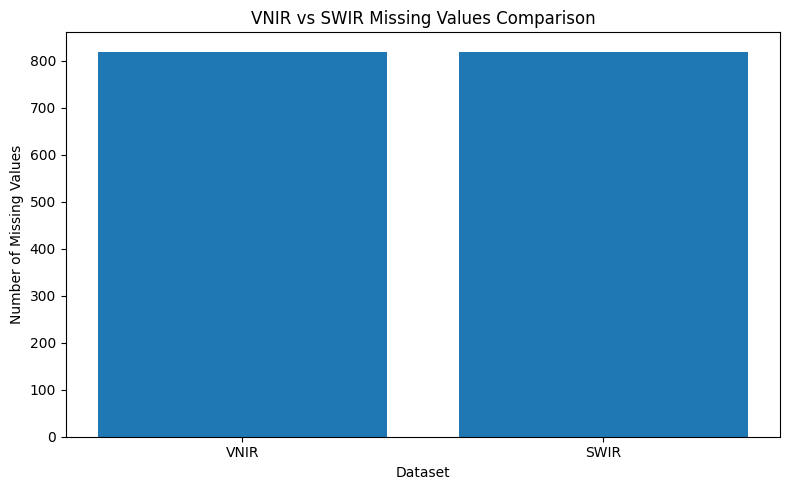


MISSING VALUES ANALYSIS COMPLETED SUCCESSFULLY!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:


import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

# 1. Upload both datasets
print("Upload VNIR_data.csv and SWIR_data.csv")
uploaded = files.upload()

vnir_file = next(
    (f for f in uploaded if "vnir" in f.lower()), None
)
swir_file = next(
    (f for f in uploaded if "swir" in f.lower()), None
)

if not vnir_file or not swir_file:
    raise ValueError("Please upload both VNIR and SWIR CSV files.")

# 2. Read datasets
vnir = pd.read_csv(
    vnir_file, sep=";", skiprows=3,
    encoding="latin1", na_values=["NA", ""]
)

swir = pd.read_csv(
    swir_file, sep=";", skiprows=3,
    encoding="latin1", na_values=["NA", ""]
)

# 3. Dataset overview
print("\nVNIR Shape:", vnir.shape)
print("SWIR Shape:", swir.shape)

# 4. Calculate missing values
vnir_missing = vnir.isnull().sum().sum()
swir_missing = swir.isnull().sum().sum()

print("\nMissing Values Report")
print("---------------------")
print("VNIR Missing Values:", vnir_missing)
print("SWIR Missing Values:", swir_missing)

# 5. Create comparison report
report = pd.DataFrame({
    "Dataset": ["VNIR", "SWIR"],
    "Total Records": [len(vnir), len(swir)],
    "Total Columns": [len(vnir.columns), len(swir.columns)],
    "Missing Values": [vnir_missing, swir_missing]
})

display(report)

report.to_csv(
    "VNIR_SWIR_Missing_Values_Report.csv",
    index=False
)

# 6. Generate comparison graph
plt.figure(figsize=(8, 5))

plt.bar(
    ["VNIR", "SWIR"],
    [vnir_missing, swir_missing]
)

plt.title("VNIR vs SWIR Missing Values Comparison")
plt.xlabel("Dataset")
plt.ylabel("Number of Missing Values")

plt.tight_layout()
plt.savefig(
    "VNIR_SWIR_Missing_Values_Comparison.png",
    dpi=300
)
plt.show()

print("\nMISSING VALUES ANALYSIS COMPLETED SUCCESSFULLY!")

# 7. Download files
files.download("VNIR_SWIR_Missing_Values_Report.csv")
files.download("VNIR_SWIR_Missing_Values_Comparison.png")